# Qwen3.5-27B Metric-vs-Ordinal Boundary Audit

前一个冻结实验发现：LoRA 大幅改善距离相关 outcome，并压低重量捷径；但绝对距离准确率没有提高、显式 net torque 反而下降，而且 near-boundary 场景显著失败。

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/ee3a9ad1c6123160.md)


In [ ]:
# Notebook utilities: support/visualtorque_checks.py
import base64 as _vt_base64, gzip as _vt_gzip, sys as _vt_sys, types as _vt_types
_vt_source = _vt_gzip.decompress(_vt_base64.b64decode("H4sIAAAAAAACCo1Y647bthL+76dgtziwtLGVTZAGqFs3J8BJkABJESCLoqjXFWiJsnmWElWS2qx7Afo0fbA+SWd4kSnJ23Z/JBLnPvPNcOSLi4vXXDBSHFhxqwltStJIw3ZS3pKS61bQI+kMF9xwpjPyrSS1LJkgUhF23zLFa9YYUrKWNSVrCmS6uLiY8bqVypCqawojpdDh4ED1QfBdeFUsPOmjnlVK1uRgapG1VGmmiKe9uX7/7oM9cSwtNagkkD/A62w2K1lFKgglRxsJ8qSrGYG/ku+ZNmQdjGf6QJ9+8TxJLfUTNwerwolkEiJJ5mo3TwnVINKUgjk9+FdB3MWha24Jbwg3TCWC1ruSrjxnphgtkydXT5+RS4L/pQuym8/Tk4aTR1nXltSwxOpzzihmOtUE+oHduydw1cXnPM8xzDhCLzZ35NWcPBpnYiqf7455Q2uW2JepstjUiQX0AAFyGZFnljw9diZ3R8M0UhMIlj7s8Kg4lvlMBhqpair4z9ZgckdFx0Z+G+WPoRa1vGOtYhW/T3pbqCl/8/LjG3BXsayQdYsxqnny4uvPNi+XP9Dlz1fLL/NtmrxYbeCJLquXy9fbX54/++3X+P3Z1W/AMhQB7fn1q++v8/dv37/6CBaSuWH35jH0EW/mC+LeEOP9S03VbSk/NfMQInpEC5MjNcF/FjY5TK+/lU2IFprs4wHQz5rQpqz0bAsiW8NlQ4U4klvGWt7sCYVY75jSfAfNLqC7u9Y2qoUjGFUMdBQsqakpDhFcbSohDnue7ZXsWt84+KfRBaBars3qydUWKjn/8/c/sKLucPl8te35eeV9JFzjnCEY0bA3eOW1QoN5XhxK7nFjSVvymTc5FI1QYKkD4lDBesTRgx6oMZosUDLd7RKfoAXBimCpCkG1Jvl33Ob0Got1GlRh9EBm85w33OR5opmonHgoaJRn3cEwTdKs5y5kA/UyeXGgChCs16+p0CxKPWjLnDL7GGpvX0CogbaBMGNzC7LZDuVlVWlmkG9zdZ6UgTyM9qTO8N/UDsAaawOtU/GmtDNwfoPYtokZOSiQTgUYwErP+qS4aZlrQ5UxdB9yQ/cLQo1RcWYAEHCOJqGHC8Vbg62jzVGw8VwdmQSxiUWIYmBvami9Huj5Wwtng8LR5Q1EIy9g+0HVDnH9kSthCUYG8wA1DiqextqDEPQHMg4NCN4AfAspurohPsg9M63UUUfbILEqgcPjYIPSZEmeYIc7HdPEeNhltMV1IEmsooXX94gIuFltRhbB0XQ883Ay/t3Me8foHbMQ4bvOIKTBr1uEvUUGPiAw3MzgNd0zmwhAjwH1/cTz+8V62L6D1oz4soqxMnF9H50WQmrmU4dt4aOFyBd+bNo2wakL4kHIpSgCBer1jbpZWR3bMDzhf3sMKv0Q9WMJT0eZC9fIg9n7nLyDVAFQteENxQtCg7oa7iXSaQo5WIC/hehKvC5sVomRVs8S94SSgGe8AlM6C1mwkwMGAdw/3OANerO9STY/ptvLm/TXgzGtfrF6/Hjz443++pvtozTMiMEKMM/+L3mD6TGIYE7+Q54SBqNuiPvW5nYM+egPK8AXxOlpoApdDT1mmJXUE6DZ/LpFYUFq2GLXw4t6mj+7y0LWoo5EtKLTKI9zI7rdhyGE4kyZ+9t/GvPMNzUgtAFcNEXvr+DaRAj6nDS7CvciQ+ASqTmUhZK6E7i2Q9PCRoQlhWLu8EUqrCV2CFRU0WPW68FC2IkTiuL2qOiS1KAU6CEViZOY1sUX1wk4eKArOsF1BNCs19cKNGN0XilMLG/e5uF0O3tVvUmfAm/xfH4g4jTWM+oUKICfo9Mq9zGWvHDT9tTgtnKArWjDG8z2QHc6xtMdzzbIso0Q5GAYEx0ahykdpPO0evzPLX4fDXx01M5cfsd1RwUU+acOr1ekgDnM9uyhjcRxxbsIzvKTsHs4iX9ScH1F28wDkpnjm2yz6QQmeC/4rWpgw0HGGbLP6fBDzKIb8m1pZ+5p5wBSI82V6OCjCOmRtrD+xe47xjROG9yWePX0mcO5ONXiuZJYm+f1SMxhoYNiHjxRJ5dU7eHuury8/YRPYeJAjCjmdx9Tys7vPiVTKl5++lr1to86mIyXD8cW7d7hg/8k6N2dn0MSGHdb6DjZI6OLETa91n4I4/chbEC5/3JJYP4xBcBn5iDL3GmAPHT424K3JRXfw7UlohjPSdlODoOzl4GAbbCQz17Y0yaRep/OhOoXNPv+3/6XDUAZbXWvL+3h0nY7mNOHB2rrXcSTYTLxBL8bB9MKD2FDh8XJats8WW1PhYU+qfp0IVacoaFadxbmmnflDMcmKIqnlPVhTJ+0cUjBJGKXMp+P7Gy6w4yK4XSuvl5JAJId/EL0QIKRKcRoZXxtsTb9VUs24viVuyDAWfzFwm2NxYGLctkqWTAYskJC1sDIEW4gIfoF0n6lgq0ArWidU8dh5u1PVm8/HCGKJvxkBSjMeWuPTmW8L1hryFvL8Uopqc59HzhURh/g6MQ6Vpik/+DhRNFkHDkN4y616jL/lkMloHd8PXAq4V05/xeSBygCsNvhnLu1xX4yoY7wChid92EMxhNqemA65aj5TN8667CHN7C6KraH5Qm/WVvFctU1eQFUkBonIR3JP2gxhq5PrX3/C0ov0eJaFQAA"))
_vt_checks = _vt_types.ModuleType("visualtorque_checks")
exec(compile(_vt_source, "<visualtorque_checks>", "exec"), _vt_checks.__dict__)
_vt_sys.modules["visualtorque_checks"] = _vt_checks
_vt_checks.install_display()
del _vt_source


In [1]:
# Run once. Every later code cell reports progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 14 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 14 tracked cells.


In [2]:
%%cell_progress 1/14 Mount Drive and select a complete VisualTorque project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Auditing candidate project roots')
from pathlib import Path
import shutil

PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
REQUIRED_TOOLKIT_PATHS = (
    'pyproject.toml',
    'src/visual_torque_toolkit/__init__.py',
    'src/visual_torque_toolkit/contracts.py',
    'src/visual_torque_toolkit/classify.py',
    'src/visual_torque_toolkit/dataset.py',
    'src/visual_torque_toolkit/edits.py',
    'src/visual_torque_toolkit/generate.py',
    'src/visual_torque_toolkit/prompts.py',
    'src/visual_torque_toolkit/render.py',
    'src/visual_torque_toolkit/splits.py',
    'src/visual_torque_toolkit/world.py',
    'src/visual_torque_toolkit/behavior/__init__.py',
    'src/visual_torque_toolkit/behavior/adapter.py',
    'src/visual_torque_toolkit/behavior/data.py',
    'src/visual_torque_toolkit/behavior/schema.py',
)

def missing_toolkit_paths(project_root):
    toolkit_root = project_root / 'toolkit'
    return [
        relative for relative in REQUIRED_TOOLKIT_PATHS
        if not (toolkit_root / relative).is_file()
    ]

candidate_audit = {
    str(candidate): missing_toolkit_paths(candidate)
    for candidate in PROJECT_CANDIDATES
}
complete_candidates = [
    candidate for candidate in PROJECT_CANDIDATES
    if not candidate_audit[str(candidate)]
]
assert complete_candidates, (
    'No complete VisualTorque toolkit was found. '
    f'Missing-file audit: {candidate_audit}'
)
PROJECT_ROOT = complete_candidates[0]

cell_stage('Copying immutable toolkit source to local SSD')
DRIVE_TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
TOOLKIT_ROOT = Path('/content/visualtorque_toolkit_runtime')
if TOOLKIT_ROOT.exists():
    shutil.rmtree(TOOLKIT_ROOT)
shutil.copytree(DRIVE_TOOLKIT_ROOT, TOOLKIT_ROOT)
print('Project:', PROJECT_ROOT)
print('Toolkit runtime:', TOOLKIT_ROOT)


Mount Drive and select a complete VisualTorque project:   0%|          | 0/14 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque
Toolkit runtime: /content/visualtorque_toolkit_runtime


In [3]:
%%cell_progress 2/14 Install and verify the frozen evaluation environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring caches before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing incompatible optional Torch packages')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio', 'torchao'],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0', 'peft==0.20.0', 'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66', 'scikit-learn>=1.5',
    'scipy>=1.13', 'pandas>=2.2', 'matplotlib>=3.8',
    'joblib>=1.4', 'pillow>=10.4',
])

cell_stage('Importing the immutable toolkit copy')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if module_name == 'visual_torque_toolkit' or module_name.startswith('visual_torque_toolkit.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import PeftModel
from scipy.stats import binomtest
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter
from visual_torque_toolkit.generate import (
    GenerationConfig, generate_multi_stack_scenes,
)
from visual_torque_toolkit.prompts import QuestionKind, generate_questions
from visual_torque_toolkit.render import RenderStyle, render_scene

# Defensive Qwen3.5 compatibility patch for exact candidate scoring.
def append_text_prefix_aligned(self, inputs, prefix):
    if not prefix:
        return inputs
    batch_size = inputs['input_ids'].shape[0]
    prefix_tensor = torch.tensor(
        prefix,
        dtype=inputs['input_ids'].dtype,
        device=inputs['input_ids'].device,
    ).unsqueeze(0).expand(batch_size, -1)
    inputs['input_ids'] = torch.cat((inputs['input_ids'], prefix_tensor), dim=1)
    attention_extension = torch.ones(
        (batch_size, len(prefix)),
        dtype=inputs['attention_mask'].dtype,
        device=inputs['attention_mask'].device,
    )
    inputs['attention_mask'] = torch.cat(
        (inputs['attention_mask'], attention_extension), dim=1
    )
    for key in ('token_type_ids', 'mm_token_type_ids'):
        if key not in inputs:
            continue
        extension = torch.zeros(
            (batch_size, len(prefix)),
            dtype=inputs[key].dtype,
            device=inputs[key].device,
        )
        inputs[key] = torch.cat((inputs[key], extension), dim=1)
    inputs.pop('position_ids', None)
    return inputs

HuggingFaceMultimodalAdapter._append_text_prefix = append_text_prefix_aligned
torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents
try:
    torchao_version = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    torchao_version = None
assert torchao_version is None
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
print('Toolkit:', toolkit_path)


Install and verify the frozen evaluation environment:   7%|7         | 1/14 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
Toolkit: /content/visualtorque_toolkit_runtime/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/14 Freeze the metric-vs-ordinal protocol
cell_stage('Checking GPU, Dataset v1 bounds, and immutable training artifacts')
import hashlib
import itertools
import math
from collections import Counter, defaultdict
from contextlib import contextmanager
from datetime import datetime, timezone
from zipfile import ZipFile

from visual_torque_toolkit.world import Scene, Side, Stack

assert torch.cuda.is_available(), 'Select a GPU runtime.'
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
assert GPU_MEMORY_GIB >= 88, (GPU_NAME, GPU_MEMORY_GIB)

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
EXPECTED_LAYER_COUNT = 64
SEED = 20260914
EVAL_BATCH_SIZE = 2
BOOTSTRAP_REPLICATES = 10000
SIGN_FLIP_REPLICATES = 10000
RUN_VERSION = 'v1'

PAIRS_PER_ORIENTATION = 6
BOUNDARY_PER_ORIENTATION_OUTCOME = 3
BALANCE_PER_ORIENTATION = 4
SCENES_PER_TRACK = (
    2 * 2 * PAIRS_PER_ORIENTATION
    + 2 * 2 * BOUNDARY_PER_ORIENTATION_OUTCOME
    + 2 * BALANCE_PER_ORIENTATION
)
assert SCENES_PER_TRACK == 44

TRAIN_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_bf16_lora_weight_shortcut_v1'
ADAPTER_DIR = TRAIN_ROOT / 'adapter_final'
ADAPTER_MANIFEST_PATH = TRAIN_ROOT / 'ADAPTER_MANIFEST.json'
TRAIN_MANIFEST_PATH = TRAIN_ROOT / 'manifests' / 'train_manifest.jsonl'
for required in (
    ADAPTER_DIR / 'adapter_config.json',
    ADAPTER_MANIFEST_PATH, TRAIN_MANIFEST_PATH,
):
    assert required.is_file(), required

def json_default(value):
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    if torch.is_tensor(value) and value.numel() == 1:
        return value.item()
    raise TypeError(f'Cannot serialize {type(value).__name__}')

def write_json_atomic(file_path, value):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(
            value, indent=2, ensure_ascii=False, sort_keys=True,
            default=json_default,
        ) + '\n',
        encoding='utf-8',
    )
    temporary.replace(file_path)

def write_jsonl_atomic(file_path, rows):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, ensure_ascii=False, sort_keys=True,
                default=json_default,
            ) + '\n')
    temporary.replace(file_path)

def read_jsonl(file_path):
    with Path(file_path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

from visualtorque_checks import sha256_file_by_name as sha256_file

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

adapter_manifest = json.loads(ADAPTER_MANIFEST_PATH.read_text(encoding='utf-8'))
assert adapter_manifest['base_model_id'] == MODEL_ID
assert adapter_manifest['base_model_revision'] == MODEL_REVISION

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / f'qwen27b_base_vs_lora_metric_vs_ordinal_boundary_{RUN_VERSION}'
)
DATASET_DIR = OUTPUT_ROOT / 'metric_vs_ordinal_dataset'
NATIVE_DIR = OUTPUT_ROOT / 'native_scores'
LORA_DIR = OUTPUT_ROOT / 'lora_scores'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for directory in (
    OUTPUT_ROOT, DATASET_DIR, NATIVE_DIR, LORA_DIR,
    ANALYSIS_DIR, FIGURE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print('GPU:', GPU_NAME, '| memory GiB:', round(GPU_MEMORY_GIB, 1))
print('Scenes per track:', SCENES_PER_TRACK)
print('Output:', OUTPUT_ROOT)


Freeze the metric-vs-ordinal protocol:  14%|#4        | 2/14 [00:00<?, ?cell/s]

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | memory GiB: 95.0
Scenes per track: 44
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1


In [5]:
%%cell_progress 4/14 Build matched ordinal-flip and boundary scene pools
cell_stage('Locating Dataset v1 and verifying the original factor bounds')
REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
SOURCE_DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
DRIVE_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(dataset_path):
    return dataset_path.is_dir() and all(
        (dataset_path / filename).is_file()
        for filename in REQUIRED_DATASET_FILES
    )

if not dataset_complete(SOURCE_DATASET_DIR):
    SOURCE_DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            extraction_root = SOURCE_DATASET_DIR.resolve()
            for member in tqdm(
                [item for item in bundle.infolist() if not item.is_dir()],
                desc='Extracting Dataset v1', unit='file',
            ):
                target = (SOURCE_DATASET_DIR / member.filename).resolve()
                if extraction_root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, SOURCE_DATASET_DIR)
        if not dataset_complete(SOURCE_DATASET_DIR):
            nested = [
                item for item in SOURCE_DATASET_DIR.iterdir()
                if dataset_complete(item)
            ]
            assert len(nested) == 1, nested
            SOURCE_DATASET_DIR = nested[0]
    elif dataset_complete(DRIVE_DATASET_DIR):
        shutil.copytree(DRIVE_DATASET_DIR, SOURCE_DATASET_DIR, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(
            'Place dataset_v1.zip or a complete dataset_v1 directory '
            'under VisualTorque/data on Drive.'
        )
assert dataset_complete(SOURCE_DATASET_DIR)

source_config = json.loads(
    (SOURCE_DATASET_DIR / 'dataset_config.json').read_text(encoding='utf-8')
)
SOURCE_MAX_DISTANCE = int(source_config['generation']['max_distance'])
SOURCE_MAX_UNITS = int(source_config['generation']['max_units'])
assert SOURCE_MAX_DISTANCE == 6, SOURCE_MAX_DISTANCE
assert SOURCE_MAX_UNITS == 5, SOURCE_MAX_UNITS

source_scene_records = read_jsonl(SOURCE_DATASET_DIR / 'scenes.jsonl')
train_manifest = read_jsonl(TRAIN_MANIFEST_PATH)
train_scene_ids = {row['scene_id'] for row in train_manifest}

def scene_from_record(record, scene_id, metadata):
    stacks = tuple(
        Stack(
            str(stack['stack_id']), Side(str(stack['side'])),
            int(stack['distance']), int(stack['units']),
        ) for stack in record['stacks']
    )
    return Scene(
        scene_id=scene_id, stacks=stacks,
        metadata=tuple((str(key), str(value)) for key, value in metadata.items()),
    )

def single_values(scene):
    left = next(stack for stack in scene.stacks if stack.side is Side.LEFT)
    right = next(stack for stack in scene.stacks if stack.side is Side.RIGHT)
    return left.units, left.distance, right.units, right.distance

def compare(left, right, balanced='equal'):
    if left > right:
        return 'left'
    if left < right:
        return 'right'
    return balanced

def mirror_signature(scene):
    left_units, left_distance, right_units, right_distance = single_values(scene)
    return right_units, right_distance, left_units, left_distance

def scene_signature(scene):
    return single_values(scene)

def mirror_cluster(scene):
    own = scene_signature(scene)
    mirrored = mirror_signature(scene)
    canonical = min(own, mirrored)
    return 'mirror_' + hashlib.sha256(repr(canonical).encode('utf-8')).hexdigest()[:16]

def candidate_row(scene, track, source_scene_id=None):
    left_units, left_distance, right_units, right_distance = single_values(scene)
    weight_relation = compare(left_units, right_units)
    distance_relation = compare(left_distance, right_distance)
    torque_relation = scene.outcome.value
    return {
        'scene': scene,
        'scene_id': scene.scene_id,
        'source_scene_id': source_scene_id,
        'track': track,
        'left_units': left_units,
        'left_distance': left_distance,
        'right_units': right_units,
        'right_distance': right_distance,
        'left_torque': scene.left_torque,
        'right_torque': scene.right_torque,
        'net_torque': scene.net_torque,
        'outcome': scene.outcome.value,
        'weight_relation': weight_relation,
        'distance_relation': distance_relation,
        'torque_relation': torque_relation,
        'weight_gap': abs(left_units - right_units),
        'distance_gap': abs(left_distance - right_distance),
        'abs_net_torque': abs(scene.net_torque),
        'mirror_cluster_id': mirror_cluster(scene),
    }

cell_stage('Creating the SFT-unseen in-range pool')
in_range_pool = []
for record in source_scene_records:
    if record['split'] != 'probe_test' or len(record['stacks']) != 2:
        continue
    assert record['scene_id'] not in train_scene_ids
    scene = scene_from_record(
        record,
        f"metric_inrange__{record['scene_id']}",
        {'track': 'in_range_sft_unseen', 'source_scene_id': record['scene_id']},
    )
    in_range_pool.append(candidate_row(
        scene, 'in_range_sft_unseen', record['scene_id']
    ))

cell_stage('Enumerating new distance-7-through-10 scenes')
extrapolation_pool = []
for left_units in range(1, SOURCE_MAX_UNITS + 1):
    for left_distance in range(1, 11):
        for right_units in range(1, SOURCE_MAX_UNITS + 1):
            for right_distance in range(1, 11):
                if max(left_distance, right_distance) <= SOURCE_MAX_DISTANCE:
                    continue
                scene_id = (
                    f'metric_ood_lu{left_units}_ld{left_distance}_'
                    f'ru{right_units}_rd{right_distance}'
                )
                scene = Scene(
                    scene_id,
                    (
                        Stack('l0', Side.LEFT, left_distance, left_units),
                        Stack('r0', Side.RIGHT, right_distance, right_units),
                    ),
                    metadata=(('track', 'distance_extrapolation'),),
                )
                extrapolation_pool.append(candidate_row(
                    scene, 'distance_extrapolation'
                ))

def conflict_orientation(row):
    if (
        row['weight_relation'] in ('left', 'right')
        and row['distance_relation'] in ('left', 'right')
        and row['weight_relation'] != row['distance_relation']
    ):
        return f"weight_{row['weight_relation']}__distance_{row['distance_relation']}"
    return None

def relation_strength(row):
    weight_ratio = max(row['left_units'], row['right_units']) / min(
        row['left_units'], row['right_units']
    )
    distance_ratio = max(row['left_distance'], row['right_distance']) / min(
        row['left_distance'], row['right_distance']
    )
    return math.log(weight_ratio), math.log(distance_ratio)

def pair_cost(first, second):
    first_weight, first_distance = relation_strength(first)
    second_weight, second_distance = relation_strength(second)
    return (
        abs(first_weight - second_weight)
        + abs(first_distance - second_distance)
        + 0.01 * abs(first['abs_net_torque'] - second['abs_net_torque'])
    )

def select_track(pool, track):
    selected = []
    pair_records = []
    used_scene_ids = set()
    orientations = (
        ('left', 'right'),
        ('right', 'left'),
    )

    # Each pair has the same ordinal cues but opposite correct outcomes.
    for weight_relation, distance_relation in orientations:
        eligible = [
            row for row in pool
            if row['weight_relation'] == weight_relation
            and row['distance_relation'] == distance_relation
            and row['outcome'] in ('left', 'right')
            and row['abs_net_torque'] >= 3
        ]
        weight_wins = [
            row for row in eligible if row['outcome'] == weight_relation
        ]
        distance_wins = [
            row for row in eligible if row['outcome'] == distance_relation
        ]
        candidate_pairs = sorted(
            (
                pair_cost(first, second), stable_key((
                    track, weight_relation, distance_relation,
                    first['scene_id'], second['scene_id'],
                )), first, second
            )
            for first in weight_wins
            for second in distance_wins
        )
        chosen = 0
        for match_cost, _, first, second in candidate_pairs:
            if first['scene_id'] in used_scene_ids or second['scene_id'] in used_scene_ids:
                continue
            pair_id = (
                f"{track}__ordinal_pair__w{weight_relation[0]}_d{distance_relation[0]}_"
                f"{chosen:02d}"
            )
            for row, member in (
                (first, 'weight_wins'), (second, 'distance_wins')
            ):
                selected.append({
                    **row,
                    'stratum': 'ordinal_flip',
                    'gap_bin': 'clear_3_plus',
                    'ordinal_orientation': conflict_orientation(row),
                    'pair_id': pair_id,
                    'pair_member': member,
                    'pair_match_cost': float(match_cost),
                })
                used_scene_ids.add(row['scene_id'])
            pair_records.append({
                'pair_id': pair_id,
                'track': track,
                'weight_relation': weight_relation,
                'distance_relation': distance_relation,
                'weight_wins_scene_id': first['scene_id'],
                'distance_wins_scene_id': second['scene_id'],
                'match_cost': float(match_cost),
            })
            chosen += 1
            if chosen == PAIRS_PER_ORIENTATION:
                break
        assert chosen == PAIRS_PER_ORIENTATION, (
            track, weight_relation, distance_relation, chosen
        )

    # Exact small-gap cases, balanced over cue orientation and winning side.
    for weight_relation, distance_relation in orientations:
        for outcome in ('left', 'right'):
            candidates = sorted(
                [
                    row for row in pool
                    if row['scene_id'] not in used_scene_ids
                    and row['weight_relation'] == weight_relation
                    and row['distance_relation'] == distance_relation
                    and row['outcome'] == outcome
                    and row['abs_net_torque'] in (1, 2)
                ],
                key=lambda row: stable_key((
                    track, 'boundary', weight_relation,
                    distance_relation, outcome, row['scene_id'],
                )),
            )
            chosen = candidates[:BOUNDARY_PER_ORIENTATION_OUTCOME]
            assert len(chosen) == BOUNDARY_PER_ORIENTATION_OUTCOME, (
                track, weight_relation, distance_relation, outcome, len(chosen)
            )
            for row in chosen:
                selected.append({
                    **row,
                    'stratum': 'near_boundary',
                    'gap_bin': 'boundary_1_2',
                    'ordinal_orientation': conflict_orientation(row),
                    'pair_id': None,
                    'pair_member': (
                        'weight_wins' if outcome == weight_relation
                        else 'distance_wins'
                    ),
                    'pair_match_cost': None,
                })
                used_scene_ids.add(row['scene_id'])

    # Exact balance despite unequal and opposing weight/distance cues.
    for weight_relation, distance_relation in orientations:
        candidates = sorted(
            [
                row for row in pool
                if row['scene_id'] not in used_scene_ids
                and row['weight_relation'] == weight_relation
                and row['distance_relation'] == distance_relation
                and row['outcome'] == 'balanced'
            ],
            key=lambda row: stable_key((
                track, 'balance', weight_relation,
                distance_relation, row['scene_id'],
            )),
        )
        chosen = candidates[:BALANCE_PER_ORIENTATION]
        assert len(chosen) == BALANCE_PER_ORIENTATION, (
            track, weight_relation, distance_relation, len(chosen)
        )
        for row in chosen:
            selected.append({
                **row,
                'stratum': 'exact_balance',
                'gap_bin': 'exact_zero',
                'ordinal_orientation': conflict_orientation(row),
                'pair_id': None,
                'pair_member': 'balanced',
                'pair_match_cost': None,
            })
            used_scene_ids.add(row['scene_id'])

    assert len(selected) == SCENES_PER_TRACK, (track, len(selected))
    assert len(used_scene_ids) == SCENES_PER_TRACK
    return selected, pair_records

in_range_selected, in_range_pairs = select_track(
    in_range_pool, 'in_range_sft_unseen'
)
ood_selected, ood_pairs = select_track(
    extrapolation_pool, 'distance_extrapolation'
)
selection_rows = [*in_range_selected, *ood_selected]
pair_records = [*in_range_pairs, *ood_pairs]

assert len(selection_rows) == 88
assert len(pair_records) == 24
assert len({row['scene_id'] for row in selection_rows}) == 88
assert not {
    row['source_scene_id'] for row in selection_rows
    if row['source_scene_id'] is not None
} & train_scene_ids
assert all(
    max(row['left_distance'], row['right_distance']) > SOURCE_MAX_DISTANCE
    for row in selection_rows if row['track'] == 'distance_extrapolation'
)

coverage = pd.DataFrame([
    {key: value for key, value in row.items() if key != 'scene'}
    for row in selection_rows
])
display(pd.crosstab(coverage['stratum'], coverage['track']))
display(pd.crosstab(
    [coverage['stratum'], coverage['pair_member']], coverage['track']
))
print('SFT-seen scene IDs in evaluation: 0')
print('Matched ordinal-flip pairs:', len(pair_records))


Build matched ordinal-flip and boundary scene pools:  21%|##1       | 3/14 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

track,distance_extrapolation,in_range_sft_unseen
stratum,,
exact_balance,8,8
near_boundary,12,12
ordinal_flip,24,24


track                        distance_extrapolation  in_range_sft_unseen
stratum       pair_member                                               
exact_balance balanced                            8                    8
near_boundary distance_wins                       6                    6
              weight_wins                         6                    6
ordinal_flip  distance_wins                      12                   12
              weight_wins                        12                   12

SFT-seen scene IDs in evaluation: 0
Matched ordinal-flip pairs: 24


In [6]:
%%cell_progress 5/14 Render and lock the matched audit dataset
cell_stage('Rendering two new visual styles at the correct tick ranges')
STYLES = {
    ('in_range_sft_unseen', 0): RenderStyle(
        width=960, height=480, ticks_per_side=6, beam_y=305,
        block_size=28, block_gap=3,
        background=(250, 245, 237), ink=(46, 42, 40),
        block_fill=(39, 128, 143),
    ),
    ('in_range_sft_unseen', 1): RenderStyle(
        width=1024, height=512, ticks_per_side=6, beam_y=324,
        block_size=30, block_gap=2,
        background=(240, 245, 242), ink=(36, 48, 45),
        block_fill=(176, 78, 112),
    ),
    ('distance_extrapolation', 0): RenderStyle(
        width=1280, height=576, ticks_per_side=10, beam_y=364,
        block_size=28, block_gap=3,
        background=(250, 245, 237), ink=(46, 42, 40),
        block_fill=(39, 128, 143),
    ),
    ('distance_extrapolation', 1): RenderStyle(
        width=1344, height=608, ticks_per_side=10, beam_y=384,
        block_size=30, block_gap=2,
        background=(240, 245, 242), ink=(36, 48, 45),
        block_fill=(176, 78, 112),
    ),
}

scene_records = []
public_selection_rows = []
for row_index, row in enumerate(tqdm(
    selection_rows, desc='Rendering metric-vs-ordinal audit', unit='image'
)):
    scene = row['scene']
    style_index = row_index % 2
    style_name = 'teal_shift' if style_index == 0 else 'rose_shift'
    style = STYLES[(row['track'], style_index)]
    relative_image = Path('images') / row['track'] / style_name / f'{scene.scene_id}.png'
    destination = DATASET_DIR / relative_image
    if not destination.is_file():
        render_scene(scene, destination, style)
    record = scene.to_record()
    record['split'] = row['track']
    record['image_path'] = relative_image.as_posix()
    record['metadata'] = {
        **record.get('metadata', {}),
        **{
            key: row[key] for key in (
                'stratum', 'gap_bin', 'ordinal_orientation',
                'pair_id', 'pair_member', 'pair_match_cost',
                'weight_relation', 'distance_relation', 'torque_relation',
                'mirror_cluster_id', 'source_scene_id',
            )
        },
        'audit_style': style_name,
        'sft_seen': False,
    }
    scene_records.append(record)
    public_selection_rows.append({
        key: value for key, value in row.items() if key != 'scene'
    } | {'style': style_name})

assert len(scene_records) == 88
write_jsonl_atomic(DATASET_DIR / 'scenes.jsonl', scene_records)
write_jsonl_atomic(DATASET_DIR / 'counterfactual_pairs.jsonl', [])
write_jsonl_atomic(OUTPUT_ROOT / 'scene_manifest.jsonl', public_selection_rows)
write_jsonl_atomic(OUTPUT_ROOT / 'ordinal_flip_pairs.jsonl', pair_records)
selection_by_scene = {row['scene_id']: row for row in public_selection_rows}

print('Rendered scenes:', len(scene_records))
display(pd.DataFrame(public_selection_rows).groupby(
    ['track', 'stratum'], as_index=False
).agg(
    scenes=('scene_id', 'size'),
    min_abs_net_torque=('abs_net_torque', 'min'),
    max_abs_net_torque=('abs_net_torque', 'max'),
    mirror_clusters=('mirror_cluster_id', 'nunique'),
))


Render and lock the matched audit dataset:  29%|##8       | 4/14 [00:00<?, ?cell/s]

Rendering metric-vs-ordinal audit:   0%|          | 0/88 [00:00<?, ?image/s]

Rendered scenes: 88


,track,stratum,scenes,min_abs_net_torque,max_abs_net_torque,mirror_clusters
0,distance_extrapolation,exact_balance,8,0,0,5
1,distance_extrapolation,near_boundary,12,1,2,8
2,distance_extrapolation,ordinal_flip,24,3,6,12
3,in_range_sft_unseen,exact_balance,8,0,0,4
4,in_range_sft_unseen,near_boundary,12,1,2,8
5,in_range_sft_unseen,ordinal_flip,24,3,7,12


In [7]:
%%cell_progress 6/14 Build balanced metric, relation, and outcome questions
cell_stage('Creating three-position numeric and Latin-balanced relation records')

def rotate_numeric_record(base_record, rotation, split):
    options = list(base_record['options'])
    rotated = options[rotation:] + options[:rotation]
    rebuilt = [
        {
            'label': chr(ord('A') + index),
            'text': option['text'],
            'semantic': option['semantic'],
        }
        for index, option in enumerate(rotated)
    ]
    answer = base_record['semantic_answer']
    correct_index = next(
        index for index, option in enumerate(rebuilt)
        if option['semantic'] == answer
    )
    return {
        **base_record,
        'question_id': f"{base_record['question_id']}__r{rotation}",
        'variant': f'numeric_rotation_{rotation}',
        'options': rebuilt,
        'correct_label': chr(ord('A') + correct_index),
        'split': split,
    }

def relation_records(scene, split, kind, prompt, answer, semantic_text):
    records = []
    semantics = tuple(semantic_text)
    for variant_index, permutation in enumerate(itertools.permutations(semantics)):
        options = [
            {
                'label': chr(ord('A') + index),
                'text': semantic_text[semantic],
                'semantic': semantic,
            }
            for index, semantic in enumerate(permutation)
        ]
        records.append({
            'schema_version': '1.0',
            'record_type': 'question',
            'question_id': f'q_{scene.scene_id}_{kind}_p{variant_index}',
            'scene_id': scene.scene_id,
            'question_kind': kind,
            'variant': f'permutation_{variant_index}',
            'prompt': prompt,
            'options': options,
            'correct_label': chr(ord('A') + permutation.index(answer)),
            'semantic_answer': answer,
            'split': split,
        })
    return records

DISTANCE_RELATION_TEXT = {
    'left': 'The left stack is farther from the pivot',
    'right': 'The right stack is farther from the pivot',
    'equal': 'The two stacks are equally far from the pivot',
}
TORQUE_RELATION_TEXT = {
    'left': 'The left-side torque is larger',
    'right': 'The right-side torque is larger',
    'balanced': 'The two side torques are equal',
}

question_records = []
for row in selection_rows:
    scene = row['scene']
    split = row['track']
    generated = list(generate_questions(scene))
    for question in generated:
        if question.kind is QuestionKind.OUTCOME:
            question_records.append(question.to_record(split=split))
        elif question.kind in (
            QuestionKind.LEFT_DISTANCE, QuestionKind.RIGHT_DISTANCE,
            QuestionKind.LEFT_TORQUE, QuestionKind.RIGHT_TORQUE,
            QuestionKind.NET_TORQUE,
        ):
            base = question.to_record(split=split)
            for rotation in range(3):
                question_records.append(rotate_numeric_record(base, rotation, split))

    question_records.extend(relation_records(
        scene, split, 'distance_relation',
        'Which stack is farther from the central pivot?',
        row['distance_relation'], DISTANCE_RELATION_TEXT,
    ))
    question_records.extend(relation_records(
        scene, split, 'torque_relation',
        'Which side has the larger total torque?',
        row['torque_relation'], TORQUE_RELATION_TEXT,
    ))

# Per scene: 6 outcome + 6 distance relation + 6 torque relation
# + 3 rotations for each of 5 numeric quantities.
assert len(question_records) == 88 * 33
write_jsonl_atomic(DATASET_DIR / 'questions.jsonl', question_records)
write_json_atomic(DATASET_DIR / 'splits.json', {
    track: sorted(
        row['scene_id'] for row in public_selection_rows
        if row['track'] == track
    ) for track in ('in_range_sft_unseen', 'distance_extrapolation')
})
write_json_atomic(DATASET_DIR / 'statistics.json', {
    'scene_count': len(scene_records),
    'question_count': len(question_records),
    'track_counts': dict(Counter(row['track'] for row in public_selection_rows)),
    'stratum_counts': {
        '|'.join(key): int(value)
        for key, value in Counter(
            (row['track'], row['stratum']) for row in public_selection_rows
        ).items()
    },
})
write_json_atomic(DATASET_DIR / 'dataset_config.json', {
    'schema_version': 'visualtorque-metric-vs-ordinal-audit-1.0',
    'seed': SEED,
    'in_range_source': 'Dataset v1 probe_test single-stack; excluded from SFT',
    'extrapolation_rule': 'at least one distance is 7 through 10',
    'numeric_rotations': 3,
    'relation_permutations_available': 6,
    'render_styles': {
        f'{track}|{index}': {
            key: getattr(style, key)
            for key in (
                'width', 'height', 'ticks_per_side', 'beam_y',
                'block_size', 'block_gap', 'background', 'ink', 'block_fill',
            )
        } for (track, index), style in STYLES.items()
    },
})

dataset_identity = {
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'train_manifest_sha256': sha256_file(TRAIN_MANIFEST_PATH),
    'source_dataset_hashes': {
        name: sha256_file(SOURCE_DATASET_DIR / name)
        for name in sorted(REQUIRED_DATASET_FILES)
    },
    'audit_dataset_hashes': {
        name: sha256_file(DATASET_DIR / name)
        for name in sorted(REQUIRED_DATASET_FILES)
    },
    'scene_manifest_sha256': sha256_file(OUTPUT_ROOT / 'scene_manifest.jsonl'),
    'pair_manifest_sha256': sha256_file(OUTPUT_ROOT / 'ordinal_flip_pairs.jsonl'),
}
DATASET_LOCK_PATH = OUTPUT_ROOT / 'dataset_lock.json'
if DATASET_LOCK_PATH.is_file():
    assert json.loads(DATASET_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == dataset_identity
else:
    write_json_atomic(DATASET_LOCK_PATH, {
        'identity': dataset_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Dataset questions:', len(question_records))
print('Dataset locked before model loading:', DATASET_LOCK_PATH)


Build balanced metric, relation, and outcome questions:  36%|###5      | 5/14 [00:00<?, ?cell/s]

Dataset questions: 2904
Dataset locked before model loading: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1/dataset_lock.json


In [8]:
%%cell_progress 7/14 Freeze the image and symbolic evaluation manifest
cell_stage('Selecting balanced prompt triples without model access')

config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=OUTPUT_ROOT / '_unused_behavior_config',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE, PromptCondition.SYMBOLIC_RULE),
    question_kinds=(
        'outcome', 'distance_relation', 'torque_relation',
        'left_distance', 'right_distance',
        'left_torque', 'right_torque', 'net_torque',
    ),
    splits=('in_range_sft_unseen', 'distance_extrapolation'),
    batch_size=EVAL_BATCH_SIZE,
    seed=SEED,
)
all_examples = list(load_behavior_examples(config))

def choose_three_latin(examples):
    by_gold = defaultdict(list)
    for example in examples:
        by_gold[example.gold_label].append(example)
    assert set(by_gold) == {'A', 'B', 'C'}
    assert all(len(rows) == 2 for rows in by_gold.values())
    triples = []
    for triple in itertools.product(*(by_gold[label] for label in ('A', 'B', 'C'))):
        counts = Counter(
            (label, str(semantic))
            for example in triple
            for label, semantic in example.label_to_semantic.items()
        )
        if len(counts) == 9 and set(counts.values()) == {1}:
            triples.append(triple)
    assert len(triples) == 2
    return list(min(
        triples,
        key=lambda triple: stable_key(tuple(
            example.example_id for example in triple
        )),
    ))

by_condition_scene_kind = defaultdict(list)
for example in all_examples:
    by_condition_scene_kind[
        (example.condition.value, example.scene_id, example.question_kind)
    ].append(example)

evaluation_examples = []
for scene_id in sorted(selection_by_scene, key=stable_key):
    # Image condition: three balanced variants for every measured stage.
    for kind in ('outcome', 'distance_relation', 'torque_relation'):
        rows = by_condition_scene_kind[('image_rule', scene_id, kind)]
        evaluation_examples.extend(choose_three_latin(rows))
    for kind in (
        'left_distance', 'right_distance',
        'left_torque', 'right_torque', 'net_torque',
    ):
        rows = by_condition_scene_kind[('image_rule', scene_id, kind)]
        assert len(rows) == 3
        evaluation_examples.extend(sorted(rows, key=lambda row: row.variant))

    # Symbolic diagnostic: exact scene text, relation and final decision only.
    for kind in ('outcome', 'torque_relation'):
        rows = by_condition_scene_kind[('symbolic_rule', scene_id, kind)]
        evaluation_examples.extend(choose_three_latin(rows))

# 24 image + 6 symbolic prompts per scene.
assert len(evaluation_examples) == 88 * 30
assert len({example.example_id for example in evaluation_examples}) == len(evaluation_examples)

def manifest_row(example):
    metadata = selection_by_scene[example.scene_id]
    return {
        'example_id': example.example_id,
        'question_id': example.question_id,
        'scene_id': example.scene_id,
        'condition': example.condition.value,
        'question_kind': example.question_kind,
        'variant': example.variant,
        'gold_label': example.gold_label,
        'gold_semantic': example.gold_semantic,
        **{
            key: metadata[key] for key in (
                'track', 'stratum', 'gap_bin', 'ordinal_orientation',
                'pair_id', 'pair_member', 'pair_match_cost',
                'left_units', 'left_distance', 'right_units', 'right_distance',
                'left_torque', 'right_torque', 'net_torque', 'outcome',
                'weight_relation', 'distance_relation', 'torque_relation',
                'mirror_cluster_id', 'style',
            )
        },
    }

EVALUATION_MANIFEST_PATH = OUTPUT_ROOT / 'frozen_evaluation_manifest.jsonl'
write_jsonl_atomic(
    EVALUATION_MANIFEST_PATH,
    [manifest_row(example) for example in evaluation_examples],
)

protocol_identity = {
    'schema_version': 'qwen27b-metric-vs-ordinal-protocol-1.0',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
    'evaluation_manifest_sha256': sha256_file(EVALUATION_MANIFEST_PATH),
    'seed': SEED,
    'evaluation_batch_size': EVAL_BATCH_SIZE,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'primary_track': 'in_range_sft_unseen',
    'primary_strata': ['ordinal_flip', 'near_boundary', 'exact_balance'],
    'classification_rule': (
        'Clear ordinal-matched outcome gain establishes magnitude-sensitive '
        'decision improvement. Exact metric behavior additionally requires '
        'boundary and explicit torque-stage gains. Clear gain with significant '
        'boundary worsening is classified as a coarse large-margin policy. '
        'All claims are behavioral signatures, not standalone circuit claims.'
    ),
    'secondary_rule': (
        'Distance-7-through-10 and symbolic results are secondary and cannot '
        'change the primary in-range classification.'
    ),
}
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
if PROTOCOL_LOCK_PATH.is_file():
    assert json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == protocol_identity
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

manifest_frame = pd.DataFrame([
    manifest_row(example) for example in evaluation_examples
])
display(pd.crosstab(
    [manifest_frame['condition'], manifest_frame['question_kind']],
    manifest_frame['track'],
))
print('Evaluation prompts per model:', len(evaluation_examples))
print('Protocol locked before inference:', PROTOCOL_LOCK_PATH)


Freeze the image and symbolic evaluation manifest:  43%|####2     | 6/14 [00:00<?, ?cell/s]

track                            distance_extrapolation  in_range_sft_unseen
condition     question_kind                                                 
image_rule    distance_relation                     132                  132
              left_distance                         132                  132
              left_torque                           132                  132
              net_torque                            132                  132
              outcome                               132                  132
              right_distance                        132                  132
              right_torque                          132                  132
              torque_relation                       132                  132
symbolic_rule outcome                               132                  132
              torque_relation                       132                  132

Evaluation prompts per model: 2640
Protocol locked before inference: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1/frozen_protocol.json


## Frozen model loading and inference


In [9]:
%%cell_progress 8/14 Load the pinned base model and verified LoRA adapter
cell_stage('Loading the pinned BF16 base checkpoint')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map='cuda:0',
)
adapter.model.eval()
assert not hasattr(adapter.model, 'peft_config')

cell_stage('Verifying every saved adapter file')
def hash_tree(directory):
    return {
        file_path.relative_to(directory).as_posix(): sha256_file(file_path)
        for file_path in sorted(Path(directory).rglob('*'))
        if file_path.is_file()
    }

assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files'], (
    'Saved LoRA files do not match ADAPTER_MANIFEST.json.'
)

cell_stage('Attaching LoRA read-only')
adapter.model = PeftModel.from_pretrained(
    adapter.model,
    str(ADAPTER_DIR),
    is_trainable=False,
)
adapter.model.eval()
for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in adapter.model.parameters())

def discover_decoder_layers(model):
    candidates = [
        (name, module)
        for name, module in model.named_modules()
        if (
            isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
            and name.endswith('language_model.layers')
        )
    ]
    if not candidates:
        candidates = [
            (name, module)
            for name, module in model.named_modules()
            if isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
        ]
    assert candidates, 'Could not locate the 64 decoder layers.'
    candidates.sort(key=lambda item: (item[0].count('.'), len(item[0])))
    return candidates[0]

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
print('Model class:', type(adapter.model).__name__)
print('Decoder path:', LAYER_PATH)
print('Adapter verification: passed')


Load the pinned base model and verified LoRA adapter:  50%|#####     | 7/14 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Model class: PeftModelForCausalLM
Decoder path: base_model.model.model.language_model.layers
Adapter verification: passed


In [10]:
%%cell_progress 9/14 Define exact candidate scoring and resumable shards
cell_stage('Defining Native/LoRA modes and semantic result records')

@contextmanager
def model_mode(mode):
    if mode == 'native':
        with adapter.model.disable_adapter():
            yield
    elif mode == 'lora':
        yield
    else:
        raise ValueError(mode)

def safe_example_stem(example_id):
    return hashlib.sha256(example_id.encode('utf-8')).hexdigest()[:24]

def chunks(values, size):
    values = list(values)
    for start in range(0, len(values), size):
        yield values[start:start + size]

def result_record(example, score_result, model):
    label_scores = {
        str(label): float(score)
        for label, score in score_result.logprob_by_label.items()
    }
    predicted_label = max(label_scores, key=label_scores.get)
    predicted_semantic = example.label_to_semantic[predicted_label]
    gold_score = label_scores[example.gold_label]
    incorrect_best = max(
        score for label, score in label_scores.items()
        if label != example.gold_label
    )
    metadata = selection_by_scene[example.scene_id]
    return {
        'schema_version': 'qwen27b-metric-vs-ordinal-score-1.0',
        'model': model,
        'example_id': example.example_id,
        'scene_id': example.scene_id,
        'condition': example.condition.value,
        'question_kind': example.question_kind,
        'variant': example.variant,
        'gold_label': example.gold_label,
        'gold_semantic': example.gold_semantic,
        'predicted_label': predicted_label,
        'predicted_semantic': predicted_semantic,
        'correct': predicted_label == example.gold_label,
        'correct_margin': float(gold_score - incorrect_best),
        'label_logprobs': label_scores,
        'scoring_mode': score_result.scoring_mode,
        'latency_seconds': float(score_result.latency_seconds),
        'weight_follow': bool(
            example.question_kind == 'outcome'
            and str(predicted_semantic) == metadata['weight_relation']
        ),
        'distance_follow': bool(
            example.question_kind == 'outcome'
            and str(predicted_semantic) == metadata['distance_relation']
        ),
        **{
            key: metadata[key] for key in (
                'track', 'stratum', 'gap_bin', 'ordinal_orientation',
                'pair_id', 'pair_member', 'pair_match_cost',
                'left_units', 'left_distance', 'right_units', 'right_distance',
                'left_torque', 'right_torque', 'net_torque', 'outcome',
                'weight_relation', 'distance_relation', 'torque_relation',
                'mirror_cluster_id', 'style',
            )
        },
    }

def run_or_resume(mode, output_dir):
    identity = {
        'schema_version': 'qwen27b-metric-vs-ordinal-score-identity-1.0',
        'model': mode,
        'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
        'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
        'evaluation_manifest_sha256': sha256_file(EVALUATION_MANIFEST_PATH),
        'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
        'example_count': len(evaluation_examples),
    }
    identity_path = Path(output_dir) / 'identity.json'
    if identity_path.is_file():
        assert json.loads(identity_path.read_text(encoding='utf-8')) == identity
    else:
        write_json_atomic(identity_path, identity)

    grouped = defaultdict(list)
    for example in evaluation_examples:
        metadata = selection_by_scene[example.scene_id]
        grouped[(
            example.condition.value, example.question_kind,
            metadata['track'], metadata['style'],
        )].append(example)

    with model_mode(mode):
        progress = tqdm(
            total=len(evaluation_examples),
            desc=f'{mode} metric-vs-ordinal audit', unit='prompt',
        )
        for group_key in sorted(grouped):
            for batch in chunks(grouped[group_key], EVAL_BATCH_SIZE):
                pending = [
                    example for example in batch
                    if not (
                        Path(output_dir)
                        / f'{safe_example_stem(example.example_id)}.json'
                    ).is_file()
                ]
                if pending:
                    scores = adapter.score_batch(pending)
                    assert len(scores) == len(pending)
                    for example, score in zip(pending, scores):
                        write_json_atomic(
                            Path(output_dir)
                            / f'{safe_example_stem(example.example_id)}.json',
                            result_record(example, score, mode),
                        )
                progress.update(len(batch))
        progress.close()

    rows = []
    for example in evaluation_examples:
        path = Path(output_dir) / f'{safe_example_stem(example.example_id)}.json'
        row = json.loads(path.read_text(encoding='utf-8'))
        assert row['example_id'] == example.example_id
        rows.append(row)
    write_jsonl_atomic(Path(output_dir) / 'all_scores.jsonl', rows)
    return rows

print('Resumable exact candidate scoring ready.')


Define exact candidate scoring and resumable shards:  57%|#####7    | 8/14 [00:00<?, ?cell/s]

Resumable exact candidate scoring ready.


In [11]:
%%cell_progress 10/14 Score the frozen audit with Native Qwen
cell_stage('Running Native with the LoRA adapter disabled')
native_rows = run_or_resume('native', NATIVE_DIR)
assert len(native_rows) == len(evaluation_examples)
print('Native prompts complete:', len(native_rows))


Score the frozen audit with Native Qwen:  64%|######4   | 9/14 [00:00<?, ?cell/s]

native metric-vs-ordinal audit:   0%|          | 0/2640 [00:00<?, ?prompt/s]

Native prompts complete: 2640


In [12]:
%%cell_progress 11/14 Score the identical audit with LoRA enabled
cell_stage('Running the saved LoRA without any training')
lora_rows = run_or_resume('lora', LORA_DIR)
assert len(lora_rows) == len(evaluation_examples)
print('LoRA prompts complete:', len(lora_rows))


Score the identical audit with LoRA enabled:  71%|#######1  | 10/14 [00:00<?, ?cell/s]

lora metric-vs-ordinal audit:   0%|          | 0/2640 [00:00<?, ?prompt/s]

LoRA prompts complete: 2640


## Analysis and preregistered behavioral classification


In [13]:
%%cell_progress 12/14 Aggregate ordinal, metric, boundary, and pair behavior
cell_stage('Building prompt-, scene-, and matched-pair tables')
score_frame = pd.DataFrame([*native_rows, *lora_rows])
assert len(score_frame) == 2 * len(evaluation_examples)
score_frame.to_csv(ANALYSIS_DIR / 'prompt_scores.csv', index=False)

prompt_summary = score_frame.groupby([
    'model', 'condition', 'track', 'stratum', 'question_kind'
], as_index=False).agg(
    prompts=('example_id', 'size'),
    accuracy=('correct', 'mean'),
    correct_margin=('correct_margin', 'mean'),
    latency_seconds=('latency_seconds', 'sum'),
)
prompt_summary.to_csv(ANALYSIS_DIR / 'prompt_summary.csv', index=False)

def modal_semantic(rows):
    counts = Counter(str(value) for value in rows['predicted_semantic'])
    return sorted(counts, key=lambda value: (-counts[value], value))[0]

image_frame = score_frame[score_frame['condition'] == 'image_rule'].copy()
scene_rows = []
for keys, group in image_frame.groupby(
    ['model', 'scene_id', 'track', 'stratum'], sort=True
):
    model, scene_id, track, stratum = keys
    metadata = selection_by_scene[scene_id]

    def kind_rows(kind, expected):
        rows = group[group['question_kind'] == kind]
        assert len(rows) == expected, (scene_id, kind, len(rows), expected)
        return rows

    left_distance = kind_rows('left_distance', 3)
    right_distance = kind_rows('right_distance', 3)
    distance_numeric = pd.concat([left_distance, right_distance])
    distance_relation = kind_rows('distance_relation', 3)
    left_torque = kind_rows('left_torque', 3)
    right_torque = kind_rows('right_torque', 3)
    side_torque = pd.concat([left_torque, right_torque])
    net_torque = kind_rows('net_torque', 3)
    torque_relation = kind_rows('torque_relation', 3)
    outcome = kind_rows('outcome', 3)

    metric_accuracy = float(np.mean([
        side_torque['correct'].mean(),
        net_torque['correct'].mean(),
        torque_relation['correct'].mean(),
    ]))
    metric_margin = float(np.mean([
        side_torque['correct_margin'].mean(),
        net_torque['correct_margin'].mean(),
        torque_relation['correct_margin'].mean(),
    ]))
    torque_modal = modal_semantic(torque_relation)
    outcome_modal = modal_semantic(outcome)
    scene_rows.append({
        'model': model,
        'scene_id': scene_id,
        'track': track,
        'stratum': stratum,
        'absolute_distance_accuracy': float(distance_numeric['correct'].mean()),
        'absolute_distance_margin': float(distance_numeric['correct_margin'].mean()),
        'distance_relation_accuracy': float(distance_relation['correct'].mean()),
        'distance_relation_margin': float(distance_relation['correct_margin'].mean()),
        'distance_relation_unanimous': bool(
            distance_relation['predicted_semantic'].nunique() == 1
        ),
        'side_torque_accuracy': float(side_torque['correct'].mean()),
        'side_torque_margin': float(side_torque['correct_margin'].mean()),
        'net_torque_accuracy': float(net_torque['correct'].mean()),
        'net_torque_margin': float(net_torque['correct_margin'].mean()),
        'torque_relation_accuracy': float(torque_relation['correct'].mean()),
        'torque_relation_margin': float(torque_relation['correct_margin'].mean()),
        'torque_relation_unanimous': bool(
            torque_relation['predicted_semantic'].nunique() == 1
        ),
        'explicit_metric_accuracy': metric_accuracy,
        'explicit_metric_margin': metric_margin,
        'outcome_accuracy': float(outcome['correct'].mean()),
        'outcome_margin': float(outcome['correct_margin'].mean()),
        'outcome_unanimous': bool(outcome['predicted_semantic'].nunique() == 1),
        'outcome_modal_semantic': outcome_modal,
        'torque_modal_semantic': torque_modal,
        'outcome_matches_torque_modal': bool(outcome_modal == torque_modal),
        'weight_follow_rate': float(outcome['weight_follow'].mean()),
        'distance_follow_rate': float(outcome['distance_follow'].mean()),
        **{
            key: metadata[key] for key in (
                'gap_bin', 'ordinal_orientation', 'pair_id', 'pair_member',
                'pair_match_cost', 'left_units', 'left_distance',
                'right_units', 'right_distance', 'left_torque',
                'right_torque', 'net_torque', 'outcome',
                'weight_relation', 'distance_relation', 'torque_relation',
                'abs_net_torque', 'mirror_cluster_id', 'style',
            )
        },
    })
scene_frame = pd.DataFrame(scene_rows)

symbolic = score_frame[score_frame['condition'] == 'symbolic_rule'].copy()
symbolic_rows = []
for keys, group in symbolic.groupby(['model', 'scene_id'], sort=True):
    model, scene_id = keys
    outcome = group[group['question_kind'] == 'outcome']
    torque_relation = group[group['question_kind'] == 'torque_relation']
    assert len(outcome) == len(torque_relation) == 3
    symbolic_rows.append({
        'model': model,
        'scene_id': scene_id,
        'symbolic_outcome_accuracy': float(outcome['correct'].mean()),
        'symbolic_outcome_margin': float(outcome['correct_margin'].mean()),
        'symbolic_torque_relation_accuracy': float(torque_relation['correct'].mean()),
        'symbolic_torque_relation_margin': float(torque_relation['correct_margin'].mean()),
    })
symbolic_scene = pd.DataFrame(symbolic_rows)
scene_frame = scene_frame.merge(
    symbolic_scene, on=['model', 'scene_id'], validate='one_to_one'
)
scene_frame['symbolic_minus_image_outcome'] = (
    scene_frame['symbolic_outcome_accuracy'] - scene_frame['outcome_accuracy']
)
scene_frame.to_csv(ANALYSIS_DIR / 'scene_metrics.csv', index=False)

pair_rows = []
paired_scenes = scene_frame[scene_frame['stratum'] == 'ordinal_flip']
for keys, group in paired_scenes.groupby(['model', 'track', 'pair_id'], sort=True):
    model, track, pair_id = keys
    assert len(group) == 2
    assert set(group['pair_member']) == {'weight_wins', 'distance_wins'}
    pair_rows.append({
        'model': model,
        'track': track,
        'pair_id': pair_id,
        'pair_outcome_accuracy': float(group['outcome_accuracy'].mean()),
        'pair_outcome_margin': float(group['outcome_margin'].mean()),
        'both_scenes_all_permutations_correct': bool(
            (group['outcome_accuracy'] == 1.0).all()
        ),
        'both_modal_predictions_correct': bool(
            (group['outcome_modal_semantic'] == group['outcome']).all()
        ),
        'modal_prediction_flips': bool(
            group['outcome_modal_semantic'].nunique() == 2
        ),
        'same_modal_prediction': bool(
            group['outcome_modal_semantic'].nunique() == 1
        ),
        'explicit_metric_accuracy': float(group['explicit_metric_accuracy'].mean()),
        'match_cost': float(group['pair_match_cost'].iloc[0]),
    })
pair_frame = pd.DataFrame(pair_rows)
pair_frame.to_csv(ANALYSIS_DIR / 'ordinal_pair_metrics.csv', index=False)

stage_summary = scene_frame.groupby([
    'model', 'track', 'stratum'
], as_index=False).agg(
    scenes=('scene_id', 'size'),
    absolute_distance_accuracy=('absolute_distance_accuracy', 'mean'),
    distance_relation_accuracy=('distance_relation_accuracy', 'mean'),
    side_torque_accuracy=('side_torque_accuracy', 'mean'),
    net_torque_accuracy=('net_torque_accuracy', 'mean'),
    torque_relation_accuracy=('torque_relation_accuracy', 'mean'),
    explicit_metric_accuracy=('explicit_metric_accuracy', 'mean'),
    outcome_accuracy=('outcome_accuracy', 'mean'),
    outcome_margin=('outcome_margin', 'mean'),
    weight_follow_rate=('weight_follow_rate', 'mean'),
    distance_follow_rate=('distance_follow_rate', 'mean'),
    symbolic_outcome_accuracy=('symbolic_outcome_accuracy', 'mean'),
)
stage_summary.to_csv(ANALYSIS_DIR / 'stage_summary.csv', index=False)
display(stage_summary.round(4))
display(pair_frame.groupby(['model', 'track'], as_index=False).agg(
    pairs=('pair_id', 'size'),
    pair_outcome_accuracy=('pair_outcome_accuracy', 'mean'),
    both_modal_predictions_correct=('both_modal_predictions_correct', 'mean'),
    modal_prediction_flips=('modal_prediction_flips', 'mean'),
    same_modal_prediction=('same_modal_prediction', 'mean'),
).round(4))


Aggregate ordinal, metric, boundary, and pair behavior:  79%|#######8  | 11/14 [00:00<?, ?cell/s]

,model,track,stratum,scenes,absolute_distance_accuracy,distance_relation_accuracy,side_torque_accuracy,net_torque_accuracy,torque_relation_accuracy,explicit_metric_accuracy,outcome_accuracy,outcome_margin,weight_follow_rate,distance_follow_rate,symbolic_outcome_accuracy
0,lora,distance_extrapolation,exact_balance,8,0.5625,1.0000,0.8542,0.5417,0.0000,0.4653,0.2917,-0.8594,0.1250,0.5833,0.8750
1,lora,distance_extrapolation,near_boundary,12,0.5139,1.0000,0.6944,0.2778,0.4444,0.4722,0.3889,-0.6389,0.1667,0.3056,0.5833
2,lora,distance_extrapolation,ordinal_flip,24,0.5556,0.8750,0.8472,0.3333,0.6944,0.6250,0.6111,0.5851,0.3472,0.4028,0.5694
3,lora,in_range_sft_unseen,exact_balance,8,0.5000,1.0000,0.9583,0.5417,0.0417,0.5139,0.5833,0.0260,0.0833,0.3333,1.0000
4,lora,in_range_sft_unseen,near_boundary,12,0.5833,0.9722,0.9028,0.3333,0.8056,0.6806,0.5556,0.8368,0.2222,0.3611,0.5556
5,lora,in_range_sft_unseen,ordinal_flip,24,0.5347,1.0000,0.9097,0.3889,0.7639,0.6875,0.7500,1.9271,0.3056,0.5000,0.6389
6,native,distance_extrapolation,exact_balance,8,0.5833,0.9583,0.8958,0.7500,0.0000,0.5486,0.0000,-2.0729,0.5833,0.4167,0.7500
7,native,distance_extrapolation,near_boundary,12,0.5972,0.9722,0.6528,0.4167,0.5556,0.5417,0.5000,-0.1910,0.5000,0.5000,0.6111
8,native,distance_extrapolation,ordinal_flip,24,0.4792,0.8333,0.7778,0.3056,0.5278,0.5370,0.4583,-0.1476,0.5278,0.4028,0.5417
9,native,in_range_sft_unseen,exact_balance,8,0.5833,0.9167,0.9375,0.8750,0.0000,0.6042,0.0000,-2.3177,0.5417,0.4583,0.7917


,model,track,pairs,pair_outcome_accuracy,both_modal_predictions_correct,modal_prediction_flips,same_modal_prediction
0,lora,distance_extrapolation,12,0.6111,0.2500,0.7500,0.2500
1,lora,in_range_sft_unseen,12,0.7500,0.6667,0.9167,0.0833
2,native,distance_extrapolation,12,0.4583,0.0833,0.0833,0.9167
3,native,in_range_sft_unseen,12,0.4861,0.0000,0.0000,1.0000


Classify the preregistered behavioral route signature:  86%|########5 | 12/14 [00:00<?, ?cell/s]

,scope,metric,n_scenes,n_mirror_clusters,n_units,mean,ci_low,ci_high,sign_flip_p
0,in_range_all,absolute_distance_accuracy_delta,44,24,24,-0.0417,-0.1077,0.0278,0.2783
2,in_range_all,distance_relation_accuracy_delta,44,24,24,0.0764,0.0347,0.1182,0.0046
10,in_range_all,explicit_metric_accuracy_delta,44,24,24,0.0428,-0.0243,0.1076,0.2437
12,in_range_all,outcome_accuracy_delta,44,24,24,0.2500,0.0833,0.4028,0.0079
13,in_range_all,outcome_margin_delta,44,24,24,1.6727,0.8212,2.4801,0.0010
16,in_range_all,weight_follow_rate_delta,44,24,24,-0.2917,-0.4444,-0.1319,0.0028
17,in_range_all,distance_follow_rate_delta,44,24,24,-0.0417,-0.2153,0.1319,0.6276
23,in_range_ordinal_flip,absolute_distance_accuracy_delta,24,12,12,-0.0833,-0.1597,-0.0000,0.0634
25,in_range_ordinal_flip,distance_relation_accuracy_delta,24,12,12,0.0556,0.0000,0.1250,0.2476
33,in_range_ordinal_flip,explicit_metric_accuracy_delta,24,12,12,0.0880,-0.0000,0.1782,0.1103


,track,metric,n_units,mean,ci_low,ci_high,sign_flip_p
0,in_range_sft_unseen,pair_outcome_accuracy_delta,12,0.2639,0.0972,0.4167,0.0166
1,in_range_sft_unseen,pair_outcome_margin_delta,12,1.8385,0.7465,3.0174,0.0081
2,in_range_sft_unseen,both_scenes_all_permutations_correct_delta,12,0.4167,0.1667,0.6667,0.0631
3,in_range_sft_unseen,both_modal_predictions_correct_delta,12,0.6667,0.4167,0.9167,0.0084
4,in_range_sft_unseen,modal_prediction_flips_delta,12,0.9167,0.7500,1.0000,0.0013
5,in_range_sft_unseen,same_modal_prediction_delta,12,-0.9167,-1.0000,-0.7500,0.0008
6,in_range_sft_unseen,explicit_metric_accuracy_delta,12,0.0880,0.0278,0.1435,0.0253
7,distance_extrapolation,pair_outcome_accuracy_delta,12,0.1528,0.0417,0.2639,0.0457
8,distance_extrapolation,pair_outcome_margin_delta,12,0.7326,-0.2431,1.6788,0.1742
9,distance_extrapolation,both_scenes_all_permutations_correct_delta,12,0.1667,0.0000,0.4167,0.5009


Primary classification: explicit_metric_readout_gain_without_decision_confirmation
Frozen gates: {'clear_ordinal_matched_outcome_gain': True, 'matched_pairs_improve': True, 'boundary_precision_gain': False, 'boundary_margin_significantly_worsens': False, 'explicit_metric_stage_gain': True, 'exact_balance_accuracy_improves': True}


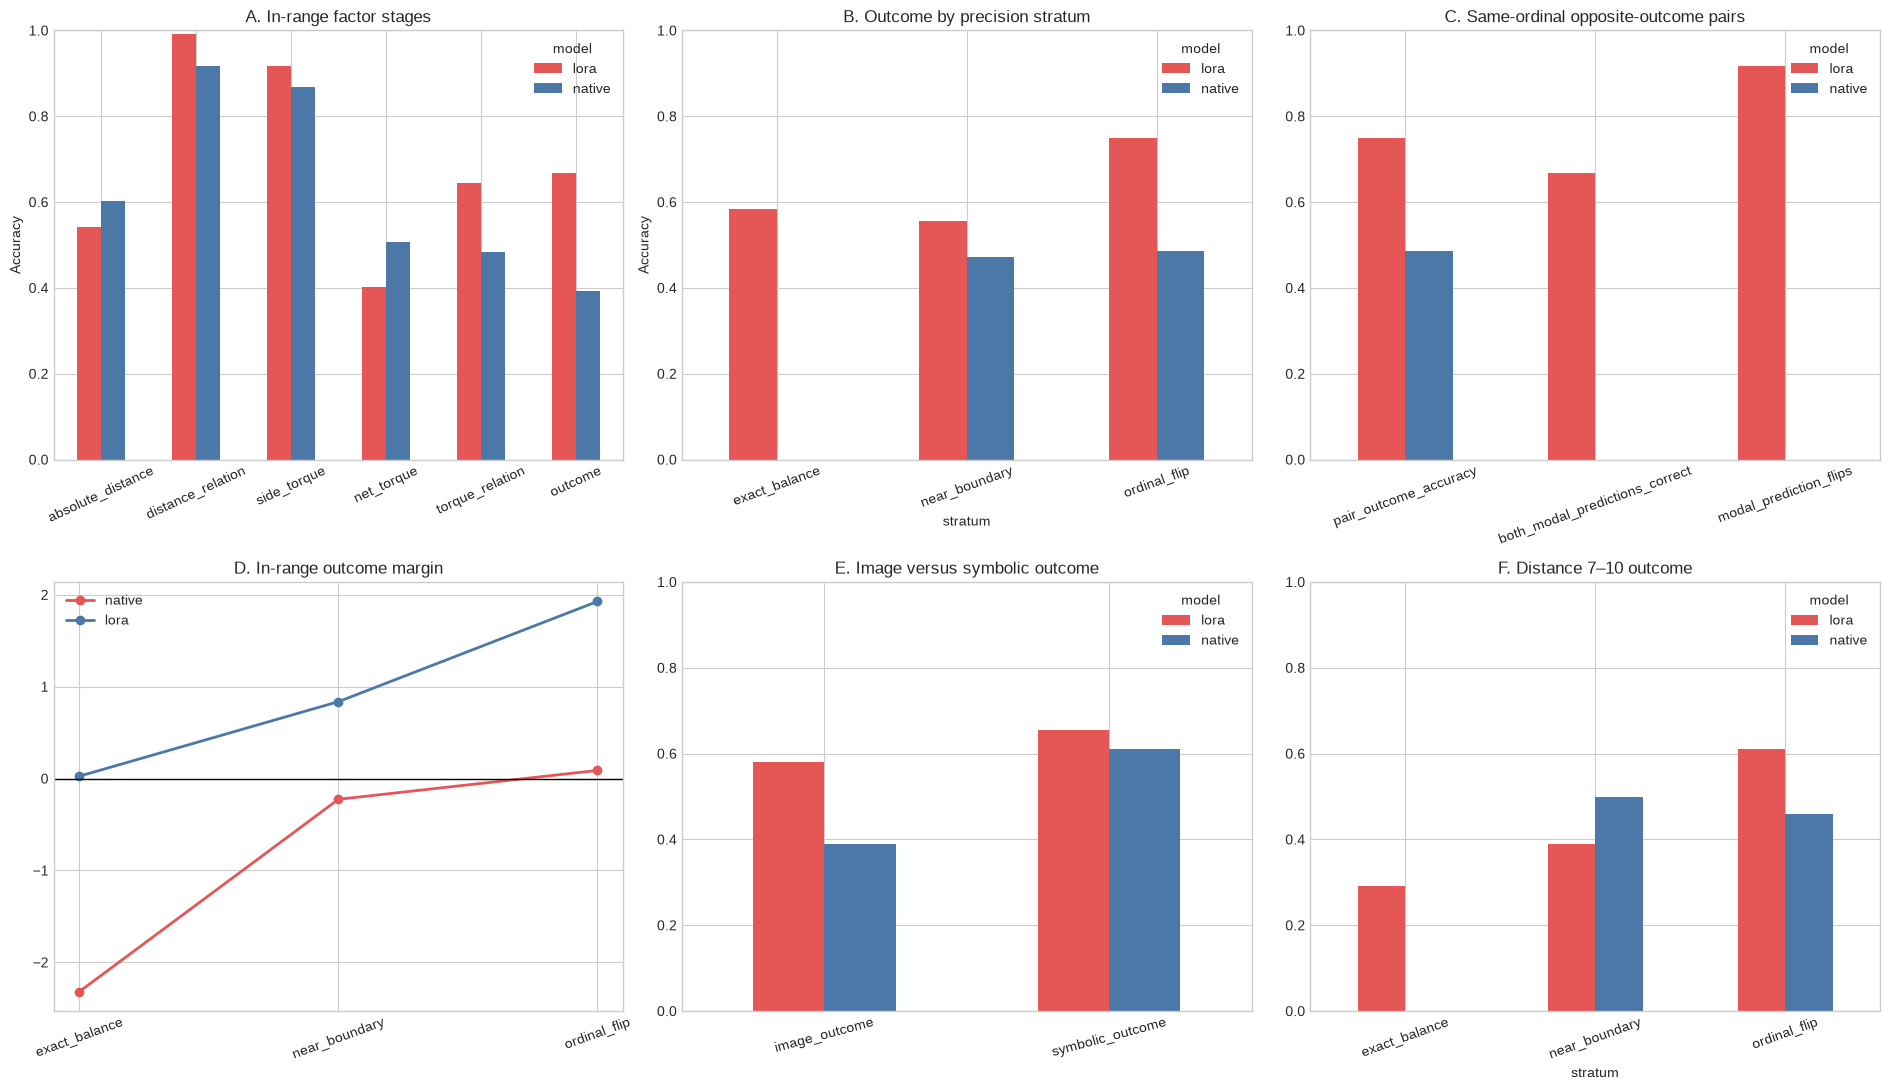

In [14]:
%%cell_progress 13/14 Classify the preregistered behavioral route signature
cell_stage('Computing mirror-clustered scene contrasts and paired diagnostics')

def bootstrap_values(values, seed):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    assert len(values)
    rng = np.random.default_rng(seed)
    draws = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
    for index in range(BOOTSTRAP_REPLICATES):
        sampled = values[rng.integers(0, len(values), size=len(values))]
        draws[index] = float(sampled.mean())
    low, high = np.quantile(draws, [0.025, 0.975])
    signs = rng.choice((-1.0, 1.0), size=(SIGN_FLIP_REPLICATES, len(values)))
    null = np.mean(signs * values[None, :], axis=1)
    p_value = float(
        (np.sum(np.abs(null) >= abs(values.mean())) + 1)
        / (SIGN_FLIP_REPLICATES + 1)
    )
    return {
        'n_units': int(len(values)),
        'mean': float(values.mean()),
        'ci_low': float(low),
        'ci_high': float(high),
        'sign_flip_p': p_value,
    }

metric_names = (
    'absolute_distance_accuracy', 'absolute_distance_margin',
    'distance_relation_accuracy', 'distance_relation_margin',
    'side_torque_accuracy', 'side_torque_margin',
    'net_torque_accuracy', 'net_torque_margin',
    'torque_relation_accuracy', 'torque_relation_margin',
    'explicit_metric_accuracy', 'explicit_metric_margin',
    'outcome_accuracy', 'outcome_margin',
    'outcome_unanimous', 'outcome_matches_torque_modal',
    'weight_follow_rate', 'distance_follow_rate',
    'symbolic_outcome_accuracy', 'symbolic_outcome_margin',
    'symbolic_torque_relation_accuracy', 'symbolic_torque_relation_margin',
    'symbolic_minus_image_outcome',
)
wide = scene_frame.pivot(
    index='scene_id', columns='model', values=list(metric_names)
)
wide.columns = ['_'.join(values) for values in wide.columns]
wide = wide.reset_index().merge(
    pd.DataFrame(public_selection_rows)[[
        'scene_id', 'track', 'stratum', 'gap_bin',
        'pair_id', 'pair_member', 'abs_net_torque', 'mirror_cluster_id',
    ]], on='scene_id', validate='one_to_one',
)
for metric in metric_names:
    wide[f'{metric}_delta'] = (
        wide[f'{metric}_lora'].astype(float)
        - wide[f'{metric}_native'].astype(float)
    )
wide.to_csv(ANALYSIS_DIR / 'paired_scene_changes.csv', index=False)

scope_masks = {
    'in_range_all': wide['track'] == 'in_range_sft_unseen',
    'in_range_ordinal_flip': (
        (wide['track'] == 'in_range_sft_unseen')
        & (wide['stratum'] == 'ordinal_flip')
    ),
    'in_range_near_boundary': (
        (wide['track'] == 'in_range_sft_unseen')
        & (wide['stratum'] == 'near_boundary')
    ),
    'in_range_exact_balance': (
        (wide['track'] == 'in_range_sft_unseen')
        & (wide['stratum'] == 'exact_balance')
    ),
    'extrapolation_all': wide['track'] == 'distance_extrapolation',
    'extrapolation_ordinal_flip': (
        (wide['track'] == 'distance_extrapolation')
        & (wide['stratum'] == 'ordinal_flip')
    ),
    'extrapolation_near_boundary': (
        (wide['track'] == 'distance_extrapolation')
        & (wide['stratum'] == 'near_boundary')
    ),
    'extrapolation_exact_balance': (
        (wide['track'] == 'distance_extrapolation')
        & (wide['stratum'] == 'exact_balance')
    ),
}

contrast_metrics = tuple(f'{metric}_delta' for metric in metric_names)
contrast_rows = []
for scope_index, (scope, mask) in enumerate(scope_masks.items()):
    group = wide[mask]
    assert len(group)
    for metric_index, metric in enumerate(contrast_metrics):
        # Average exact left/right mirrors before resampling or sign flipping.
        cluster_values = group.groupby('mirror_cluster_id')[metric].mean().to_numpy()
        contrast_rows.append({
            'scope': scope,
            'metric': metric,
            'n_scenes': int(len(group)),
            'n_mirror_clusters': int(group['mirror_cluster_id'].nunique()),
            **bootstrap_values(
                cluster_values,
                SEED + 4000 + scope_index * 100 + metric_index,
            ),
        })
scene_contrasts = pd.DataFrame(contrast_rows)
scene_contrasts.to_csv(ANALYSIS_DIR / 'scene_contrast_summary.csv', index=False)

pair_wide = pair_frame.pivot(
    index=['track', 'pair_id'], columns='model',
    values=[
        'pair_outcome_accuracy', 'pair_outcome_margin',
        'both_scenes_all_permutations_correct',
        'both_modal_predictions_correct', 'modal_prediction_flips',
        'same_modal_prediction', 'explicit_metric_accuracy',
    ],
)
pair_wide.columns = ['_'.join(values) for values in pair_wide.columns]
pair_wide = pair_wide.reset_index()
pair_metrics = (
    'pair_outcome_accuracy', 'pair_outcome_margin',
    'both_scenes_all_permutations_correct',
    'both_modal_predictions_correct', 'modal_prediction_flips',
    'same_modal_prediction', 'explicit_metric_accuracy',
)
for metric in pair_metrics:
    pair_wide[f'{metric}_delta'] = (
        pair_wide[f'{metric}_lora'].astype(float)
        - pair_wide[f'{metric}_native'].astype(float)
    )
pair_wide.to_csv(ANALYSIS_DIR / 'paired_pair_changes.csv', index=False)

pair_contrast_rows = []
for track_index, track in enumerate(
    ('in_range_sft_unseen', 'distance_extrapolation')
):
    group = pair_wide[pair_wide['track'] == track]
    assert len(group) == 12
    for metric_index, metric in enumerate(pair_metrics):
        pair_contrast_rows.append({
            'track': track,
            'metric': f'{metric}_delta',
            **bootstrap_values(
                group[f'{metric}_delta'],
                SEED + 6000 + track_index * 100 + metric_index,
            ),
        })
pair_contrasts = pd.DataFrame(pair_contrast_rows)
pair_contrasts.to_csv(ANALYSIS_DIR / 'pair_contrast_summary.csv', index=False)

def scene_contrast(scope, metric):
    row = scene_contrasts[
        (scene_contrasts['scope'] == scope)
        & (scene_contrasts['metric'] == metric)
    ]
    assert len(row) == 1
    return row.iloc[0]

def pair_contrast(track, metric):
    row = pair_contrasts[
        (pair_contrasts['track'] == track)
        & (pair_contrasts['metric'] == metric)
    ]
    assert len(row) == 1
    return row.iloc[0]

clear_accuracy = scene_contrast(
    'in_range_ordinal_flip', 'outcome_accuracy_delta'
)
clear_margin = scene_contrast(
    'in_range_ordinal_flip', 'outcome_margin_delta'
)
boundary_accuracy = scene_contrast(
    'in_range_near_boundary', 'outcome_accuracy_delta'
)
boundary_margin = scene_contrast(
    'in_range_near_boundary', 'outcome_margin_delta'
)
balance_accuracy = scene_contrast(
    'in_range_exact_balance', 'outcome_accuracy_delta'
)
metric_accuracy = scene_contrast(
    'in_range_all', 'explicit_metric_accuracy_delta'
)
metric_margin = scene_contrast(
    'in_range_all', 'explicit_metric_margin_delta'
)
pair_flip = pair_contrast(
    'in_range_sft_unseen', 'both_modal_predictions_correct_delta'
)
pair_accuracy = pair_contrast(
    'in_range_sft_unseen', 'pair_outcome_accuracy_delta'
)

gates = {
    'clear_ordinal_matched_outcome_gain': bool(
        clear_accuracy['mean'] > 0 and clear_margin['ci_low'] > 0
    ),
    'matched_pairs_improve': bool(
        pair_accuracy['mean'] > 0 and pair_flip['mean'] > 0
    ),
    'boundary_precision_gain': bool(
        boundary_accuracy['mean'] > 0 and boundary_margin['ci_low'] > 0
    ),
    'boundary_margin_significantly_worsens': bool(
        boundary_margin['ci_high'] < 0
    ),
    'explicit_metric_stage_gain': bool(
        metric_accuracy['mean'] > 0 and metric_margin['ci_low'] > 0
    ),
    'exact_balance_accuracy_improves': bool(balance_accuracy['mean'] > 0),
}

magnitude_sensitive_gain = (
    gates['clear_ordinal_matched_outcome_gain']
    and gates['matched_pairs_improve']
)
if (
    magnitude_sensitive_gain
    and gates['boundary_precision_gain']
    and gates['explicit_metric_stage_gain']
):
    primary_classification = 'exact_metric_torque_behavioral_signature'
elif magnitude_sensitive_gain and gates['boundary_margin_significantly_worsens']:
    primary_classification = 'coarse_magnitude_sensitive_policy_with_boundary_failure'
elif magnitude_sensitive_gain and not gates['explicit_metric_stage_gain']:
    primary_classification = 'magnitude_sensitive_outcome_policy_without_explicit_metric_chain'
elif gates['clear_ordinal_matched_outcome_gain'] and not gates['matched_pairs_improve']:
    primary_classification = 'possible_ordinal_replacement_shortcut'
elif gates['explicit_metric_stage_gain']:
    primary_classification = 'explicit_metric_readout_gain_without_decision_confirmation'
else:
    primary_classification = 'route_signature_not_yet_resolved'

decision = {
    'schema_version': 'qwen27b-metric-vs-ordinal-decision-1.0',
    'primary_classification': primary_classification,
    'gates': gates,
    'key_contrasts': {
        'clear_outcome_accuracy': clear_accuracy.to_dict(),
        'clear_outcome_margin': clear_margin.to_dict(),
        'boundary_outcome_accuracy': boundary_accuracy.to_dict(),
        'boundary_outcome_margin': boundary_margin.to_dict(),
        'balance_outcome_accuracy': balance_accuracy.to_dict(),
        'explicit_metric_accuracy': metric_accuracy.to_dict(),
        'explicit_metric_margin': metric_margin.to_dict(),
        'matched_pair_accuracy': pair_accuracy.to_dict(),
        'matched_pair_both_modal_correct': pair_flip.to_dict(),
    },
    'interpretation': {
        'exact_metric': (
            'Behavior is consistent with absolute factor extraction and '
            'precision-preserving torque composition, pending causal tests.'
        ),
        'coarse_magnitude': (
            'The model distinguishes outcome-flip pairs sharing the same '
            'ordinal cues, so it uses magnitude information, but loses '
            'precision near the decision boundary.'
        ),
        'ordinal_replacement': (
            'Improvement does not reliably break same-ordinal opposite-outcome '
            'pairs; a new relational shortcut remains plausible.'
        ),
    },
}
DECISION_PATH = ANALYSIS_DIR / 'metric_vs_ordinal_decision.json'
write_json_atomic(DECISION_PATH, decision)

display(scene_contrasts[
    scene_contrasts['metric'].isin([
        'absolute_distance_accuracy_delta',
        'distance_relation_accuracy_delta',
        'explicit_metric_accuracy_delta',
        'outcome_accuracy_delta', 'outcome_margin_delta',
        'weight_follow_rate_delta', 'distance_follow_rate_delta',
    ])
].round(4))
display(pair_contrasts.round(4))
print('Primary classification:', primary_classification)
print('Frozen gates:', gates)

cell_stage('Rendering the metric-vs-ordinal summary figure')
plt.style.use('seaborn-v0_8-whitegrid')
figure, axes = plt.subplots(2, 3, figsize=(19, 11))

in_range = scene_frame[scene_frame['track'] == 'in_range_sft_unseen']
factor_plot = in_range.groupby('model', as_index=False).agg(
    absolute_distance=('absolute_distance_accuracy', 'mean'),
    distance_relation=('distance_relation_accuracy', 'mean'),
    side_torque=('side_torque_accuracy', 'mean'),
    net_torque=('net_torque_accuracy', 'mean'),
    torque_relation=('torque_relation_accuracy', 'mean'),
    outcome=('outcome_accuracy', 'mean'),
).set_index('model').T
factor_plot.plot(kind='bar', ax=axes[0, 0], color=['#E45756', '#4C78A8'])
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_title('A. In-range factor stages')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].tick_params(axis='x', rotation=25)

stratum_plot = in_range.groupby(
    ['stratum', 'model']
)['outcome_accuracy'].mean().unstack()
stratum_plot.plot(kind='bar', ax=axes[0, 1], color=['#E45756', '#4C78A8'])
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_title('B. Outcome by precision stratum')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].tick_params(axis='x', rotation=20)

pair_plot = pair_frame[pair_frame['track'] == 'in_range_sft_unseen'].groupby(
    'model'
)[['pair_outcome_accuracy', 'both_modal_predictions_correct', 'modal_prediction_flips']].mean().T
pair_plot.plot(kind='bar', ax=axes[0, 2], color=['#E45756', '#4C78A8'])
axes[0, 2].set_ylim(0, 1)
axes[0, 2].set_title('C. Same-ordinal opposite-outcome pairs')
axes[0, 2].tick_params(axis='x', rotation=20)

gap_plot = scene_frame.groupby(
    ['track', 'stratum', 'model']
)['outcome_margin'].mean().reset_index()
for model, color in [('native', '#E45756'), ('lora', '#4C78A8')]:
    subset = gap_plot[
        (gap_plot['track'] == 'in_range_sft_unseen')
        & (gap_plot['model'] == model)
    ]
    axes[1, 0].plot(
        subset['stratum'], subset['outcome_margin'],
        marker='o', linewidth=2, label=model, color=color,
    )
axes[1, 0].axhline(0, color='black', linewidth=1)
axes[1, 0].set_title('D. In-range outcome margin')
axes[1, 0].tick_params(axis='x', rotation=20)
axes[1, 0].legend()

condition_plot = scene_frame.groupby('model', as_index=False).agg(
    image_outcome=('outcome_accuracy', 'mean'),
    symbolic_outcome=('symbolic_outcome_accuracy', 'mean'),
).set_index('model').T
condition_plot.plot(kind='bar', ax=axes[1, 1], color=['#E45756', '#4C78A8'])
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title('E. Image versus symbolic outcome')
axes[1, 1].tick_params(axis='x', rotation=15)

ood_plot = scene_frame[
    scene_frame['track'] == 'distance_extrapolation'
].groupby(['stratum', 'model'])['outcome_accuracy'].mean().unstack()
ood_plot.plot(kind='bar', ax=axes[1, 2], color=['#E45756', '#4C78A8'])
axes[1, 2].set_ylim(0, 1)
axes[1, 2].set_title('F. Distance 7–10 outcome')
axes[1, 2].tick_params(axis='x', rotation=20)

plt.tight_layout()
SUMMARY_FIGURE_PATH = FIGURE_DIR / 'metric_vs_ordinal_summary.png'
plt.savefig(SUMMARY_FIGURE_PATH, dpi=180, bbox_inches='tight')
plt.show()


In [15]:
%%cell_progress 14/14 Verify the complete metric-vs-ordinal package
cell_stage('Checking required outputs and exact counts')
required_outputs = (
    DATASET_LOCK_PATH, PROTOCOL_LOCK_PATH,
    OUTPUT_ROOT / 'scene_manifest.jsonl',
    OUTPUT_ROOT / 'ordinal_flip_pairs.jsonl',
    EVALUATION_MANIFEST_PATH,
    NATIVE_DIR / 'identity.json', NATIVE_DIR / 'all_scores.jsonl',
    LORA_DIR / 'identity.json', LORA_DIR / 'all_scores.jsonl',
    ANALYSIS_DIR / 'prompt_scores.csv',
    ANALYSIS_DIR / 'prompt_summary.csv',
    ANALYSIS_DIR / 'scene_metrics.csv',
    ANALYSIS_DIR / 'ordinal_pair_metrics.csv',
    ANALYSIS_DIR / 'stage_summary.csv',
    ANALYSIS_DIR / 'paired_scene_changes.csv',
    ANALYSIS_DIR / 'scene_contrast_summary.csv',
    ANALYSIS_DIR / 'paired_pair_changes.csv',
    ANALYSIS_DIR / 'pair_contrast_summary.csv',
    DECISION_PATH, SUMMARY_FIGURE_PATH,
)
missing = [str(path) for path in required_outputs if not Path(path).is_file()]
assert not missing, 'Missing required outputs:\n' + '\n'.join(missing)
assert len([
    path for path in NATIVE_DIR.glob('*.json')
    if path.name != 'identity.json'
]) == len(evaluation_examples)
assert len([
    path for path in LORA_DIR.glob('*.json')
    if path.name != 'identity.json'
]) == len(evaluation_examples)
assert len(read_jsonl(NATIVE_DIR / 'all_scores.jsonl')) == len(evaluation_examples)
assert len(read_jsonl(LORA_DIR / 'all_scores.jsonl')) == len(evaluation_examples)

completion = {
    'schema_version': 'qwen27b-metric-vs-ordinal-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_dir': str(ADAPTER_DIR),
    'in_range_sft_unseen_scenes': 44,
    'distance_extrapolation_scenes': 44,
    'ordinal_flip_pairs': 24,
    'prompts_per_model': len(evaluation_examples),
    'decision_path': str(DECISION_PATH),
    'summary_figure_path': str(SUMMARY_FIGURE_PATH),
    'required_outputs': [str(path) for path in required_outputs],
}
RUN_COMPLETE_PATH = OUTPUT_ROOT / 'RUN_COMPLETE.json'
write_json_atomic(RUN_COMPLETE_PATH, completion)
print('Metric-vs-ordinal audit complete:', RUN_COMPLETE_PATH)
print('Primary decision:', DECISION_PATH)
print('Summary figure:', SUMMARY_FIGURE_PATH)


Verify the complete metric-vs-ordinal package:  93%|#########2| 13/14 [00:00<?, ?cell/s]

Metric-vs-ordinal audit complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1/RUN_COMPLETE.json
Primary decision: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1/analysis/metric_vs_ordinal_decision.json
Summary figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1/analysis/figures/metric_vs_ordinal_summary.png
